# Setup
If you have not run the below code in a separate Julia session, this notebook will not work.
```
using Pkg
Pkg.add("DrWatson")          
Pkg.activate("path/to/temp-tune")
Pkg.instantiate()

cd("path/to/temp-tune")
include(scriptsdir("setup_python.jl"))
```

## activate project

In [1]:
using Pkg
using DrWatson
@quickactivate "temp-tune"
println("current active project = ",Base.active_project())

current active project = /Users/pfields/Git/temp-tune/Project.toml


## setup plotting

In [2]:
include(srcdir("matplotlib_helpers.jl"))
setup_notebook_for_paper()
using_Py(true)

setup_rc_reset()
set_plot_style_for_paper(; venue="revtex")

Plot style set → venue=revtex, font='Arial'
Sizes (pt): label=10.0  tick=8.0  legend=8.0  mathtext.fontset=cm
Python     : /Users/pfields/Git/temp-tune/.conda/bin/python
Matplotlib : 3.10.8 | backend=Agg
 set plot style finished. exiting...



## other packages

In [3]:
using StatsBase, Statistics, LinearAlgebra, Printf, Random
using SpecialFunctions
using Parameters, Flux
using Optim, BenchmarkTools, JLD2, DataFrames, Graphs
using OptimizationOptimJL, Optimization
using Roots, Expectations
using Distributions
using Conda

In [29]:
include(srcdir("two_level_toy_model.jl"))

get_dkl (generic function with 1 method)

# Run several experiments to find optimal tau and plot means

### run simulations and plot

In [68]:
#= for different values of training samples, M, 
and ground truth energy gaps, Delta, fit many models, 
find the corresponding optimal taus, and do so for many different
number of ground states, holding the total number of states fixed
=#

Deltas = collect(2.5:0.25:9.5)

Ms= [unique(Int.(round.(10 .^(collect(.3:0.01:2.6)))));
    unique(Int.(round.(10 .^(collect(2.7:0.09:4.5)))))]

nlevels = 2
N_states=50
fraction_nground = collect(0.2:0.05:0.3)

dirstring = "simple_model_sweeps_new"

mkpath(datadir(dirstring))

nreps=10

10

In [70]:
df_mean_fits_all_Ns_ng=run_sweep_constant_N_states_vary_nground(N_states,
                                                    fraction_nground,
                                                    Ms, Deltas, dirstring,
                                                    nlevels, nreps );

running sims for frac ground states = 0.200000
sweeps done
running sims for frac ground states = 0.250000
sweeps done
running sims for frac ground states = 0.300000
sweeps done


size(all_mean_delta_hat') = (23, 160)
size(Ms) = (160,)
size(Deltas) = (23,)

plots for nground = 10 and nexcited = 40


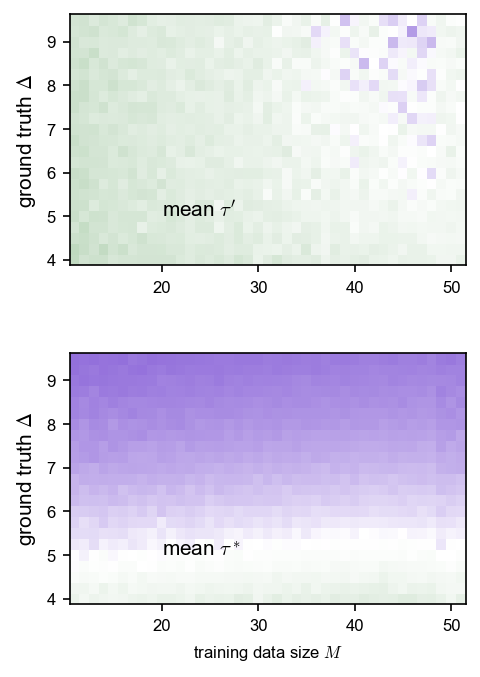

In [71]:
fig, ax = subplots(2,1,dpi=150, figsize=set_size_for_paper(1,1.5))

nground=10
nexcited=40 #determines which sim to import

fig, im1, im2 = plot_contour_fig_2(df_mean_fits_all_Ns_ng,
                                    N_states, nground, nexcited, Deltas, Ms,ax;
                    ticklabelsize=8, ylabelsize=8, xlabelsize=8 );
ax[1].text(20,5, "mean "*L"\tau'")
ax[2].text(20,5, "mean "*L"\tau^*")

println("\nplots for nground = $nground and nexcited = $nexcited")

### import sims used for paper

In [72]:
Deltas = collect(2.5:0.25:9.5)

Ms= [unique(Int.(round.(10 .^(collect(.3:0.01:2.6)))));
    unique(Int.(round.(10 .^(collect(2.7:0.09:4.5)))))]

# nexcited=85
# nground=15
nlevels = 2
N_states=100
fraction_nground = collect(0.2:0.02:0.40)

dirstring = "simple_model_sweeps"

# mkpath(datadir(dirstring))

nreps=50

50

In [73]:
df_mean_fits_all_Ns_ng = DataFrame( N_states=[], nground=[], Ms=[], Deltas=[], nreps=[], #5
                                    all_mean_n_g_hat=[], all_mean_delta_hat=[], all_mean_LL=[], 
                                    tau_stars=[], tau_primes=[], 
                                    all_std_n_g_hat=[] , all_std_delta_hat=[] , all_std_LL=[] ,
                                    all_tau_star_std=[], all_tau_prime_st=[],
                                    phase_line=[] ) 
for frac_ng in fraction_nground
    # @printf "%f\n" frac_ng
    
    nground = Int(round(frac_ng*N_states))
    
    nexcited = N_states - nground
    
    temp_dict=load( datadir(dirstring*"/Nstates=$(N_states)_nground=$nground.jld2"))
    
    push!( df_mean_fits_all_Ns_ng, temp_dict["sweep_data"])

end

In [74]:
function get_c( c_map_, all_t, t)
    norm_t = ( t - minimum(all_t) ) / ( maximum(all_t) - minimum(all_t) )
    return c_map_(Float64(norm_t))
end

get_c (generic function with 1 method)

size(all_mean_delta_hat') = (23, 160)
size(Ms) = (160,)
size(Deltas) = (23,)


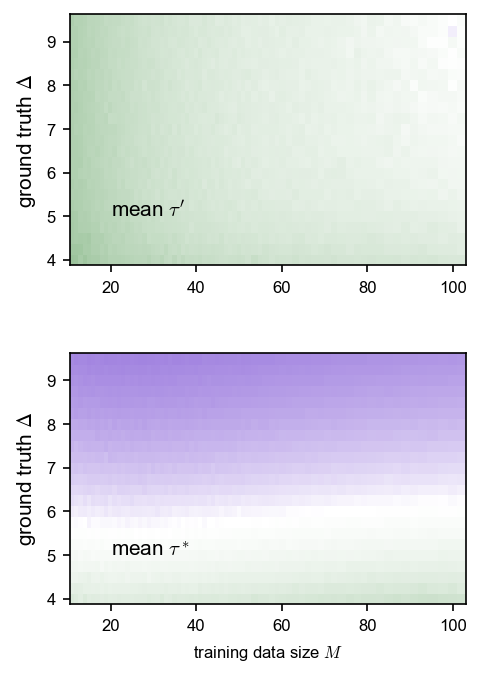

PyObject Text(20, 5, 'mean $\\tau^*$')

In [75]:
df_mean_fits_all_Ns_ng;
fig, ax = subplots(2,1,dpi=150, figsize=set_size_for_paper(1,1.5))

nground=20
nexcited =80 #determines which sim to import

fig, im1, im2 = plot_contour_fig_2(df_mean_fits_all_Ns_ng,
                                    N_states, nground, nexcited, Deltas, Ms,ax;
                    ticklabelsize=8, ylabelsize=8, xlabelsize=8 );
ax[1].text(20,5, "mean "*L"\tau'")
ax[2].text(20,5, "mean "*L"\tau^*")

# Figure 2 from paper

79

In [65]:
Ms[79]

100